# Trabajo Practico Laboratorio Unificado - Teoria de Circuitos 2

## Profesor: Mariano Llamedo Soria
## Jefe de TPs: César Fuoco

## Alumno: Ignacio Gomez Pugliese

## TPLab 1

### Objetivos
* Consolidar los conceptos de teoría moderna mediante la implementación circuital.
* Simular e implementar el filtro con componentes activos OPAMP/OTA.
* Medir las partes de la función transferencia en un ancho de banda de 10 a 100 kHz.
* Diseñar el PCB en Altium / KiCad para optimizar los resultados de la medición.


### Descripción

El trabajo práctico consiste en el diseño, análisis, medición y discusión de un filtro activo. 


### Plantilla:

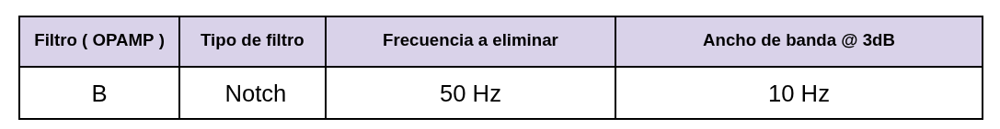

### Analisis:

Proponemos el siguiente circuito:

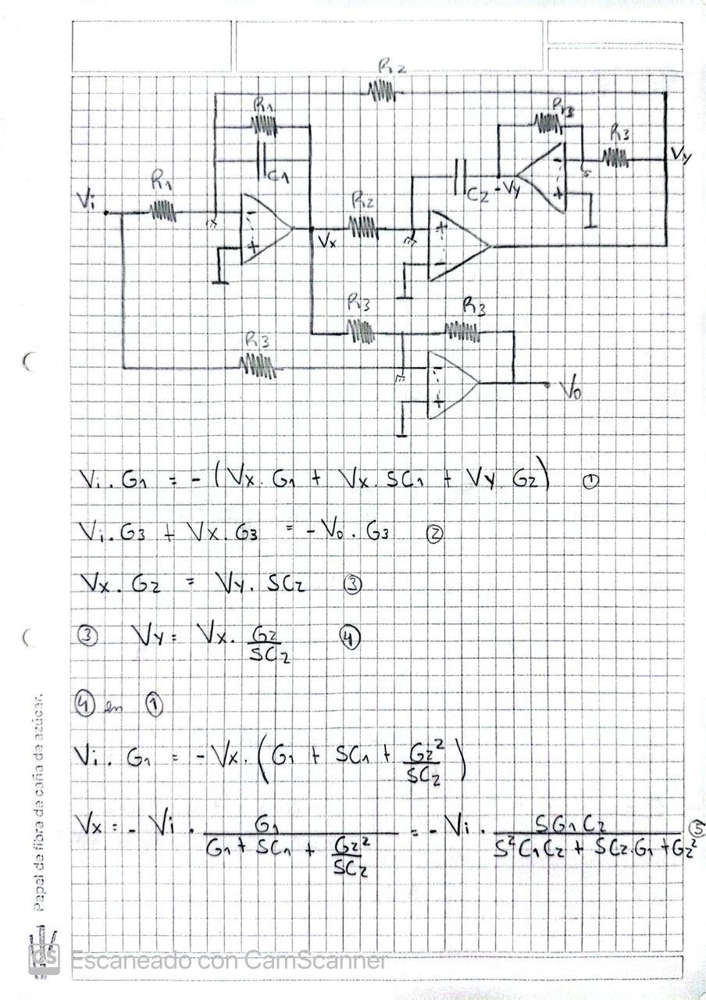
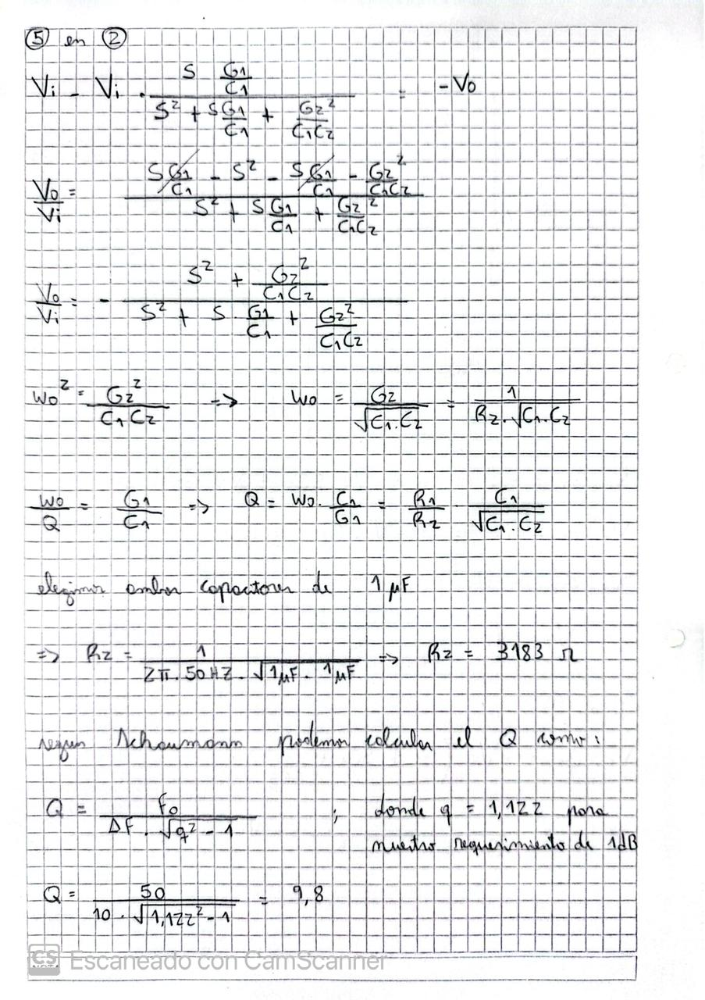
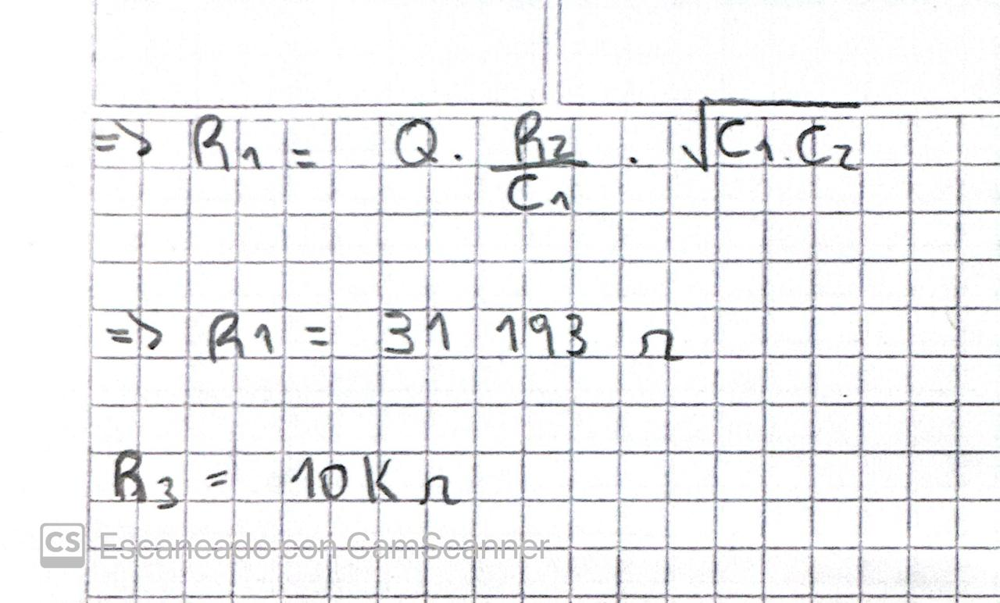

### Simulaciones numericas:

(3,
 <Axes: title={'center': 'Retardo de grupo'}, xlabel='Frecuencia angular [rad/seg]', ylabel='Retardo de grupo [seg]'>)

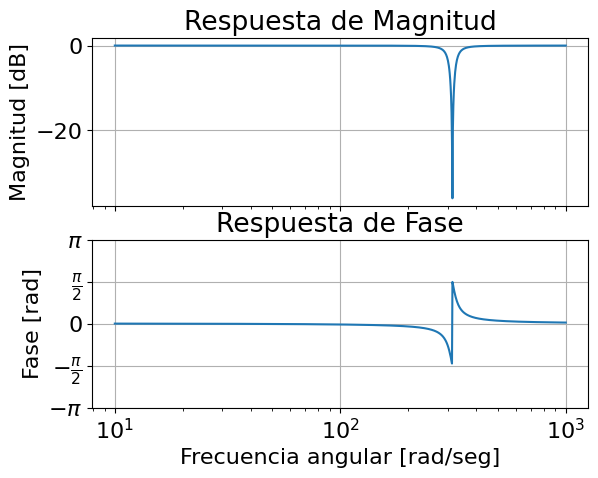

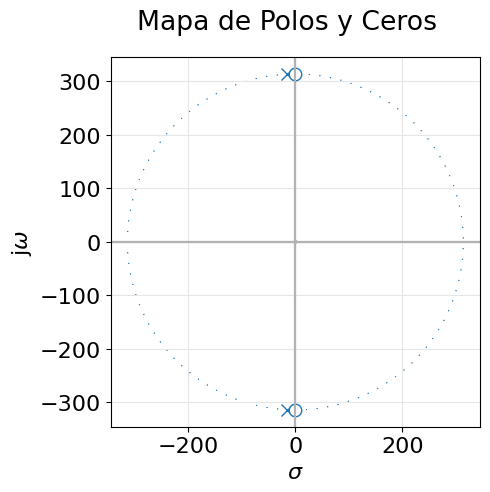

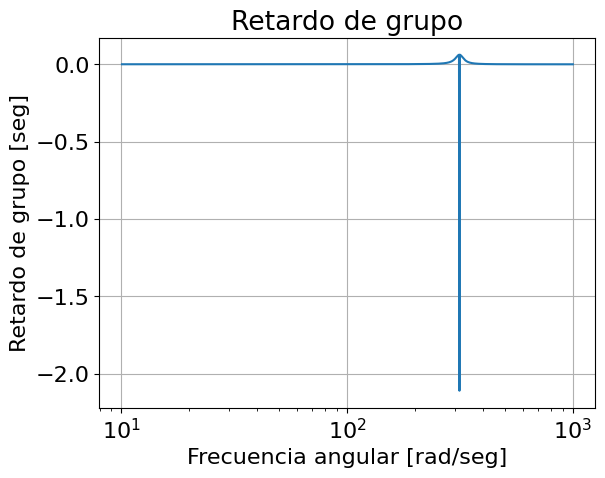

In [30]:
from scipy.signal import TransferFunction
import matplotlib.pyplot as plt
import numpy as np
import sys
from pytc2.sistemas_lineales import pzmap, GroupDelay, bodePlot

w0 = 2 * np.pi * 50
Q=9.8

my_tf = TransferFunction( [(1, 0, w0**2)], [1, w0/Q, w0**2] )


plt.close('all')

bodePlot(my_tf, fig_id=1)

pzmap(my_tf, fig_id=2) #S plane pole/zero plot

GroupDelay(my_tf, fig_id=3)

### Simulaciones circuitales:

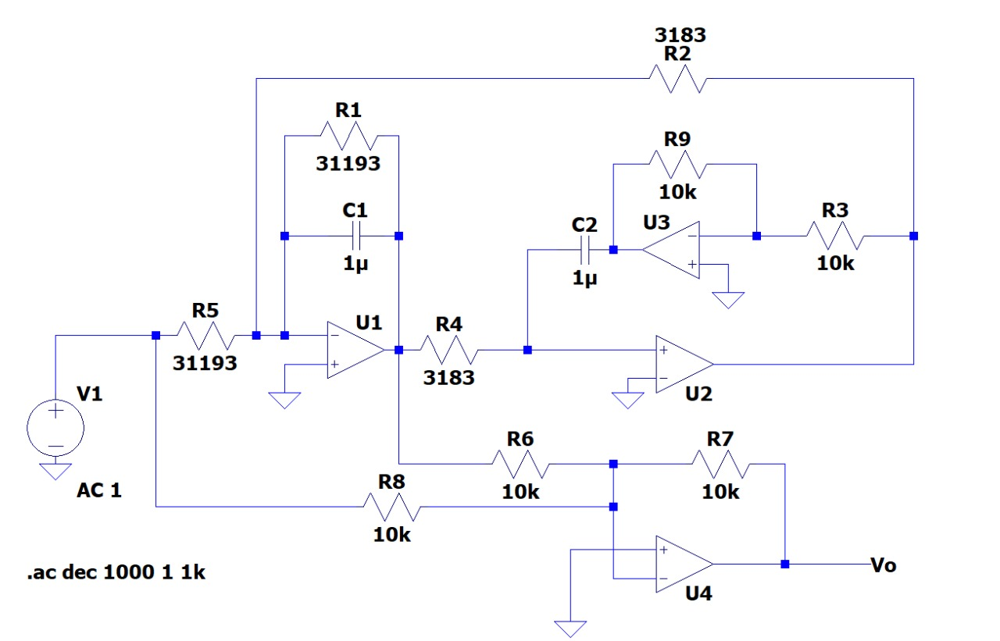
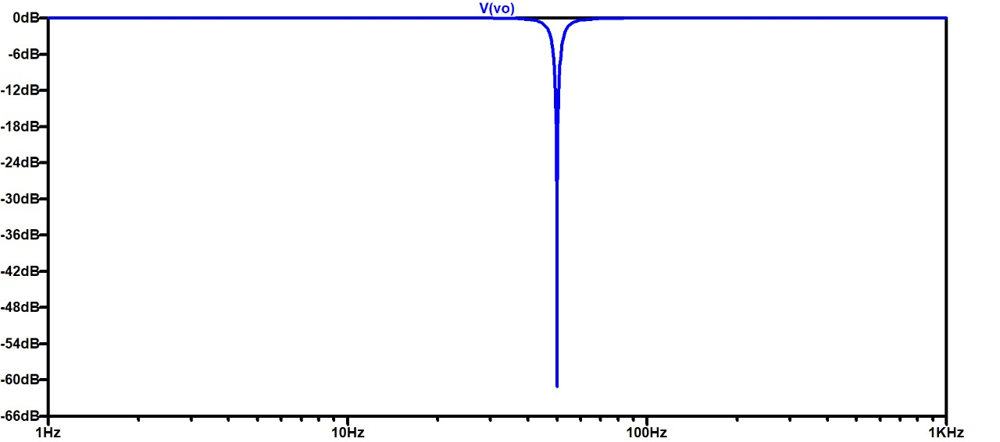
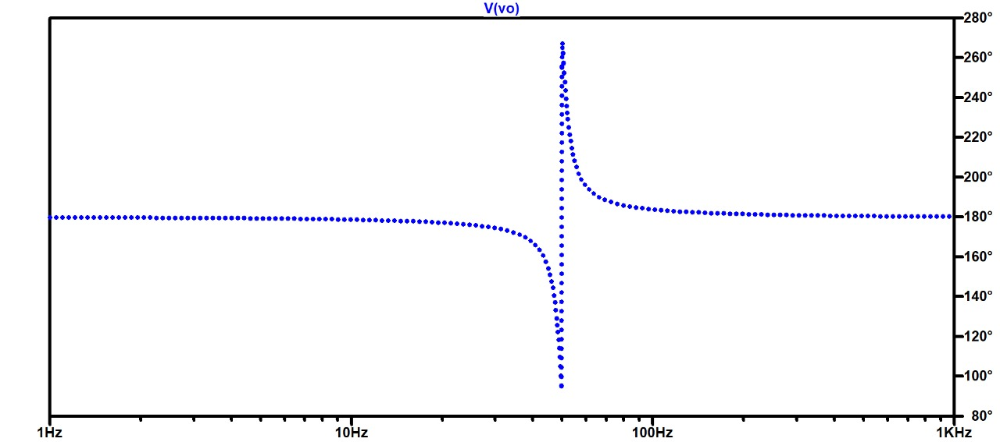
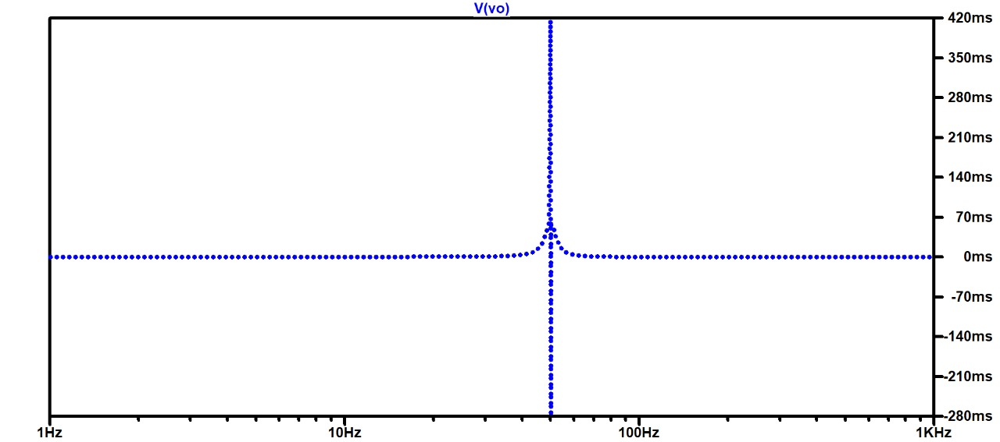

### Armado del circuito:

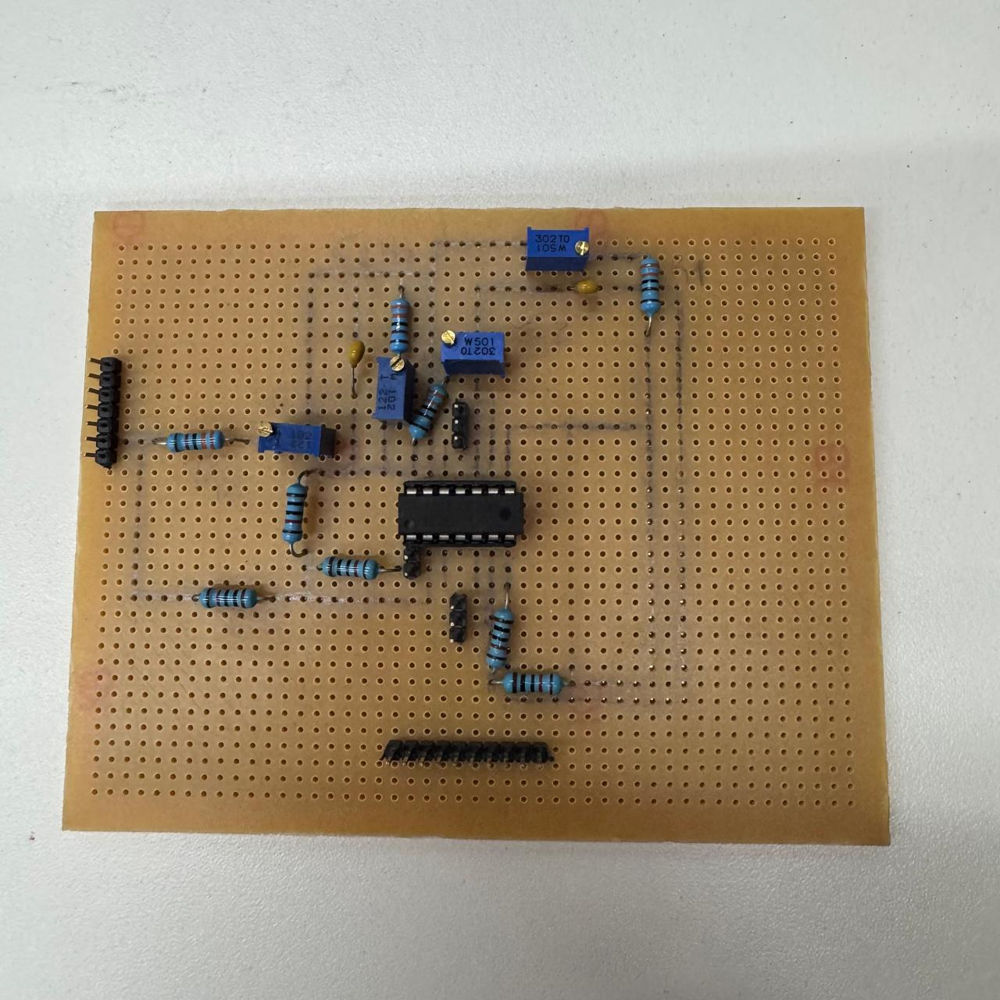
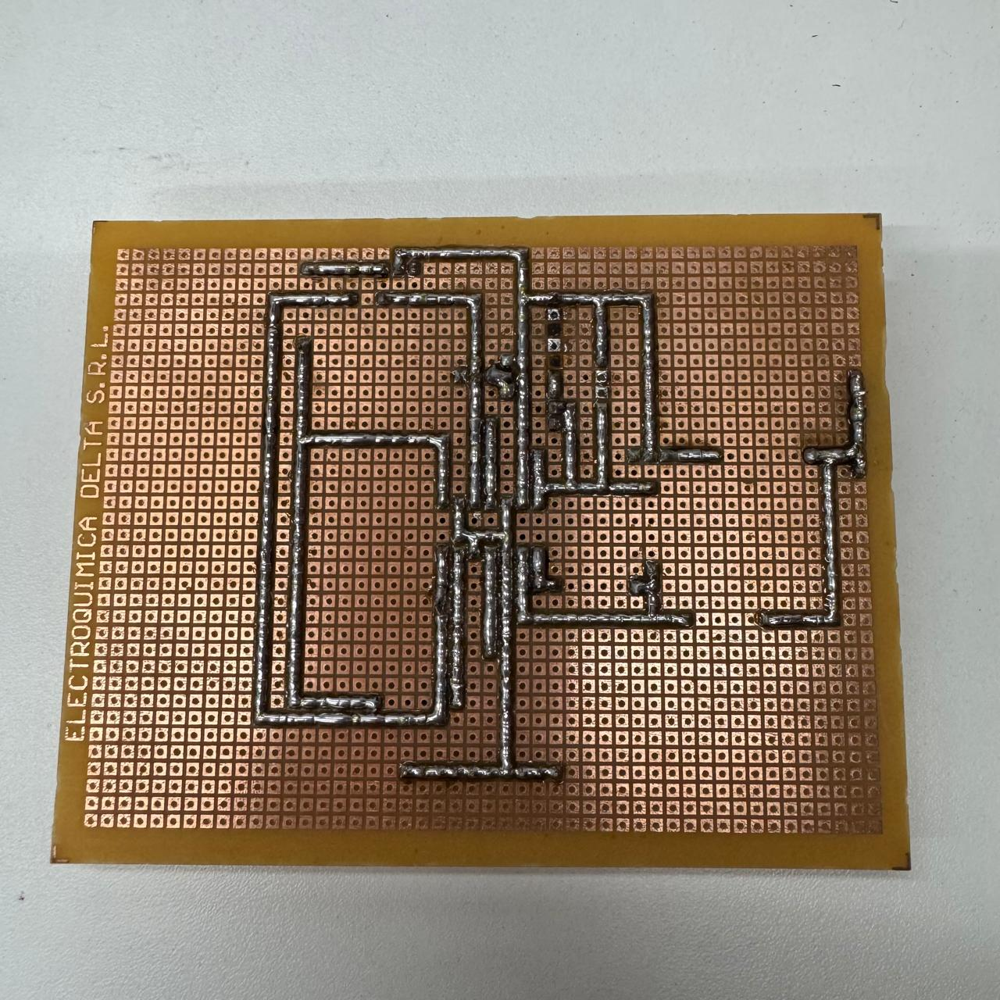

### Mediciones:

Para una Vinpp = 5V

### Osciloscopio:

In [31]:
import pandas as pd
tabla=pd.DataFrame(data = [[20,4.90,25.00,180.0,-0.17],
                           [30,5.30,16.60,179.2,0.50],
                           [40,5.03,11.80,169.9,0.05],
                           [45,3.83,9.00,145.8,-2.31],
                           [46,2.68,9.20,152.3,-5.41],
                           [47,1.87,9.80,165.8,-8.54],
                           [48,1.67,11.00,190.0,-9.52],
                           [49,2.07,11.40,201.0,-7.65],
                           [50,2.92,11.40,205.2,-4.67],
                           [51,3.35,11.60,212.9,-3.47],
                           [52,3.96,11.00,205.9,-2.02],
                           [53,4.28,10.80,206.0,-1.35],
                           [54,4.55,10.40,202.1,-0.81],
                           [55,4.71,10.20,201.9,-0.51],
                           [75,4.80,7.00,189.0,-0.35],
                           [125,5.07,4.16,187.2,0.12],
                           [250,5.03,2.00,180.0,0.05],
                           [500,5.03,1.00,180.0,0.05],
                           [1000,5.00,0.50,180.0,0.00],
                           [2000,5.00,0.25,180.0,0.00],
                           [5000,5.00,0.10,180.0,0.00]],
                   columns = ['Frecuencia(Hz)','Voutpp(V)','ΔT(ms)','Fase(°)','dB']
)
tabla

,Frecuencia(Hz),Voutpp(V),ΔT(ms),Fase(°),dB
0,20,4.90,25.00,180.0,-0.17
1,30,5.30,16.60,179.2,0.50
2,40,5.03,11.80,169.9,0.05
3,45,3.83,9.00,145.8,-2.31
4,46,2.68,9.20,152.3,-5.41
5,47,1.87,9.80,165.8,-8.54
6,48,1.67,11.00,190.0,-9.52
7,49,2.07,11.40,201.0,-7.65
8,50,2.92,11.40,205.2,-4.67
9,51,3.35,11.60,212.9,-3.47


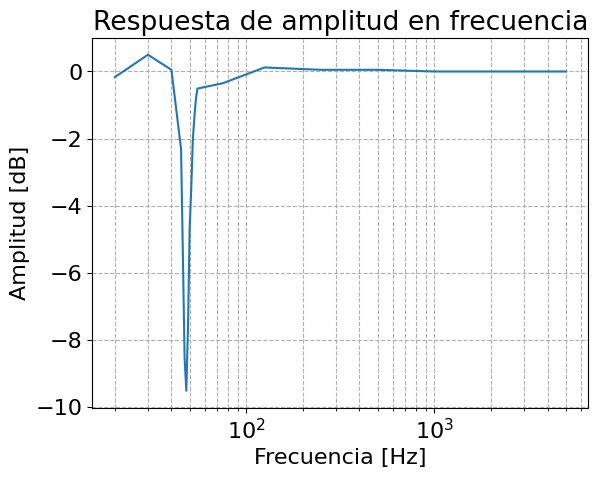

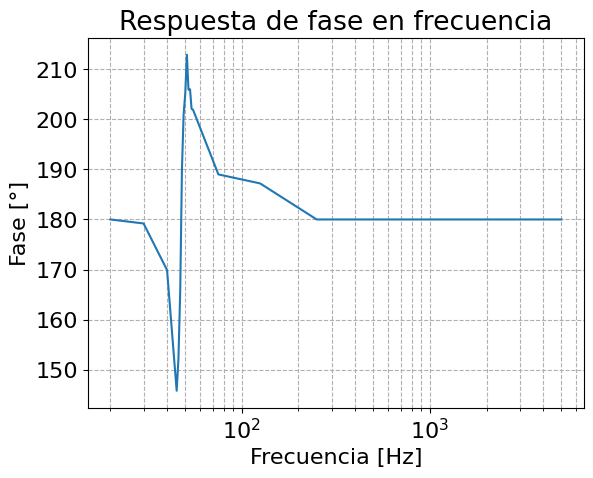

In [32]:
plt.figure()
plt.plot(tabla['Frecuencia(Hz)'], tabla['dB'])
plt.xscale('log')  # <- Esto convierte el eje x (frecuencia) a logarítmico
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dB]')
plt.title('Respuesta de amplitud en frecuencia')
plt.grid(True, which='both', ls='--')
plt.show()
plt.figure()
plt.plot(tabla['Frecuencia(Hz)'], tabla['Fase(°)'])
plt.xscale('log')  # <- Esto convierte el eje x (frecuencia) a logarítmico
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [°]')
plt.title('Respuesta de fase en frecuencia')
plt.grid(True, which='both', ls='--')
plt.show()

### Analizador de audio:

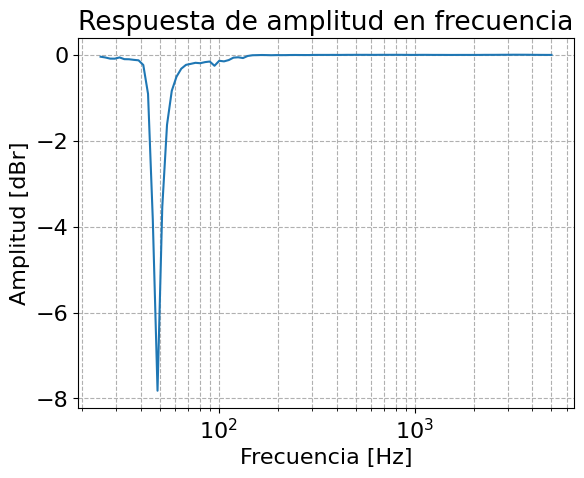

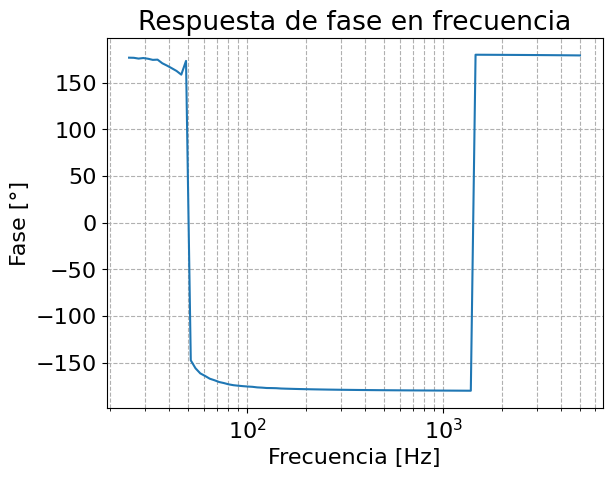

In [33]:
amplitud_ch1 = pd.read_csv('/home/ignacio/Escritorio/Facultad/2025/TC2/Tareas_Semanales/TPLab1-IgnacioGomezPugliese/Sweep_Data_0.csv', skiprows=108)
frecuencia = amplitud_ch1.iloc[2:, 0].to_numpy()
dbr = amplitud_ch1.iloc[2:, 1].to_numpy()

fase_ch1 = pd.read_csv('/home/ignacio/Escritorio/Facultad/2025/TC2/Tareas_Semanales/TPLab1-IgnacioGomezPugliese/Sweep_Data_1.csv', skiprows=108)
frecuencia = fase_ch1.iloc[2:, 0].to_numpy()
fase = fase_ch1.iloc[2:, 1].to_numpy()

plt.figure()
plt.plot(frecuencia, dbr)
plt.xscale('log')  # <- Esto convierte el eje x (frecuencia) a logarítmico
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [dBr]')
plt.title('Respuesta de amplitud en frecuencia')
plt.grid(True, which='both', ls='--')
plt.show()
plt.figure()
plt.plot(frecuencia, fase)
plt.xscale('log')  # <- Esto convierte el eje x (frecuencia) a logarítmico
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [°]')
plt.title('Respuesta de fase en frecuencia')
plt.grid(True, which='both', ls='--')
plt.show()

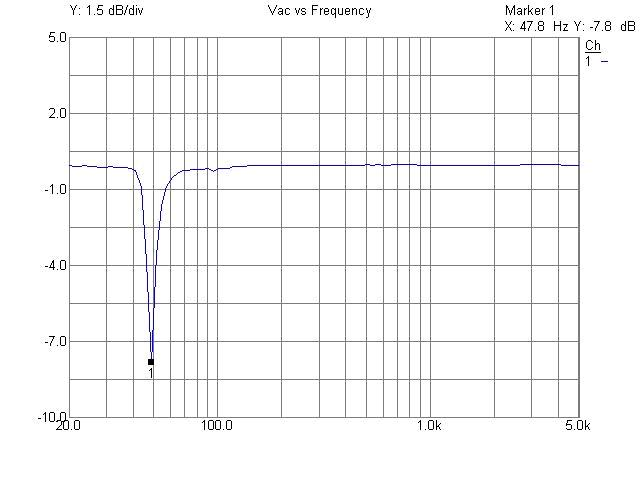

### Conclusiones:

Como conclusion podemos decir que el filtro funciono en base a lo esperado en las simulaciones, atenuando unos 8dB cerca de la frecuencia de 48 Hz.
Sabiendo los valores precisos de los capacitores y ajustando mas fino las resistencias variables podriamos mejorar esa frecuencia de eliminacion. La atenuacion que se observa en las simulaciones son mucho mas altas ya que los componentes se consideran ideales, ademas de las conexiones propias de medicion y alimentacion del circuito.

## TPLab 2

### Objetivos
* Consolidar los conceptos de los sistemas muestreados mediante el uso de ADC y DACs.
* Simular e implementar un filtro digital con el STM NUCLEO-64.
* Familiarizarse con el uso de librerías para procesamiento digital de señales.
* Medir las partes de la función transferencia H[z] para frecuencias entre 10 Hz y 10 kHz.

### Descripcion
El trabajo práctico tiene como objetivo la implementación de funciones transferencias digitales utilizando como procesador de señales el STM NUCLEO-64.

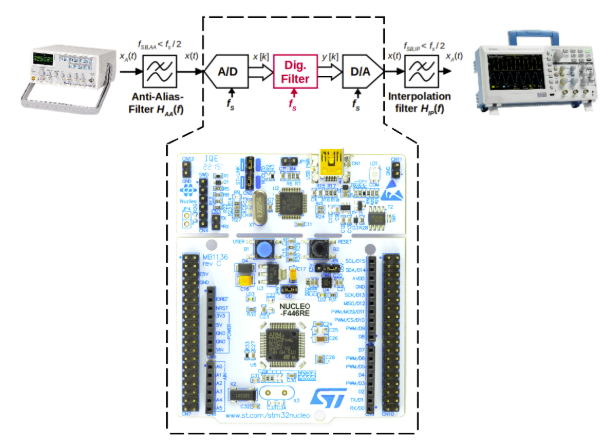

El filtro digital en sí mismo es un algoritmo. En nuestro caso para simplificar la tarea vamos a instanciar funciones de la librería de procesamiento digital de arm cmsis-dsp:

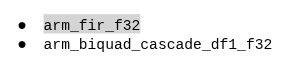


### Armado del circuito
Para poder ingresar la señal proveniente del generador de funciones correctamente al MCU deberán colocar un filtro Antialias y proporcionar un nivel de continua. Recuerden que se debe ingresar al ADC con una señal entre 0 y 3.3V.  A la salida del DAC bastará solo con replicar el filtro de entrada.
Las conexiones con el kit de desarrollo se detallan a continuación:

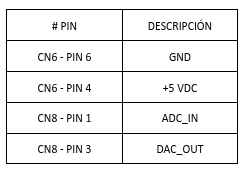

### Diseño de filtros
Se necesita eliminar las interferencias de una señal electrocardiográfica (ECG) que fue registrada a una frecuencia de muestreo de 1 kHz. Para ello se propone la siguiente plantilla de diseño:

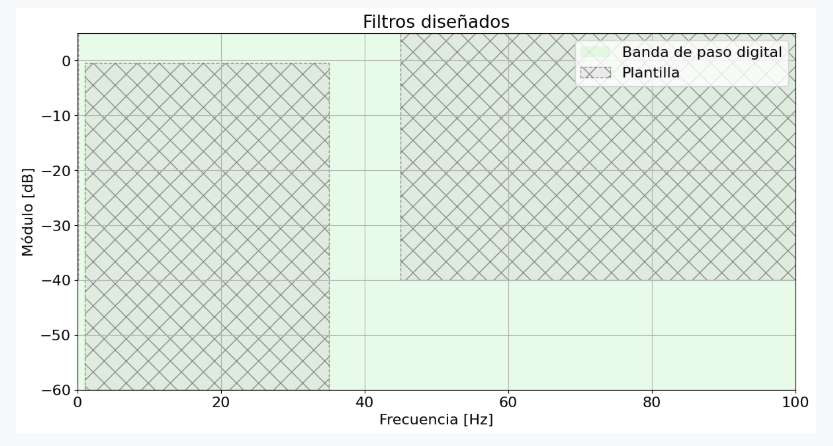

y se pide diseñar dos filtros: uno IIR y otro FIR que cumplan con la plantilla, utilizando alguno de los métodos estudiados.

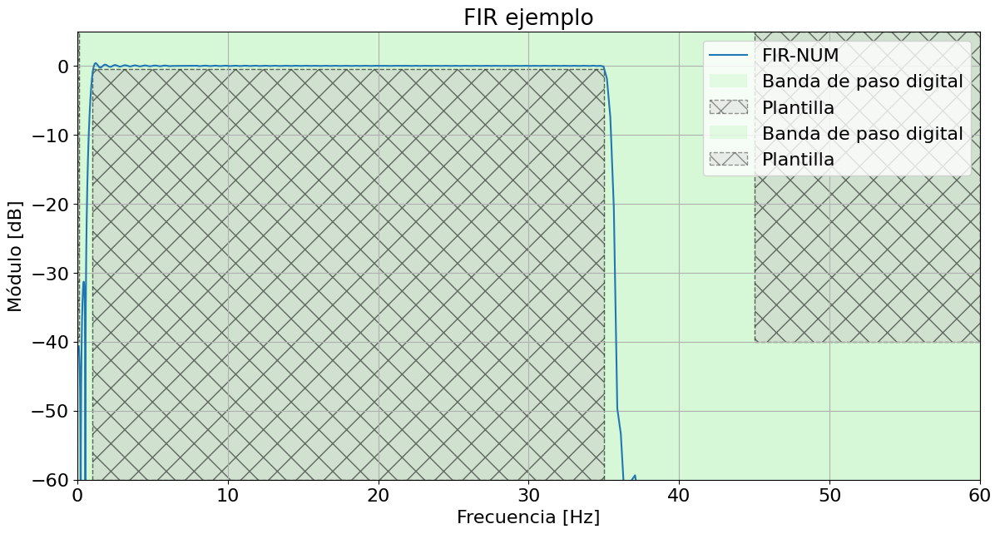

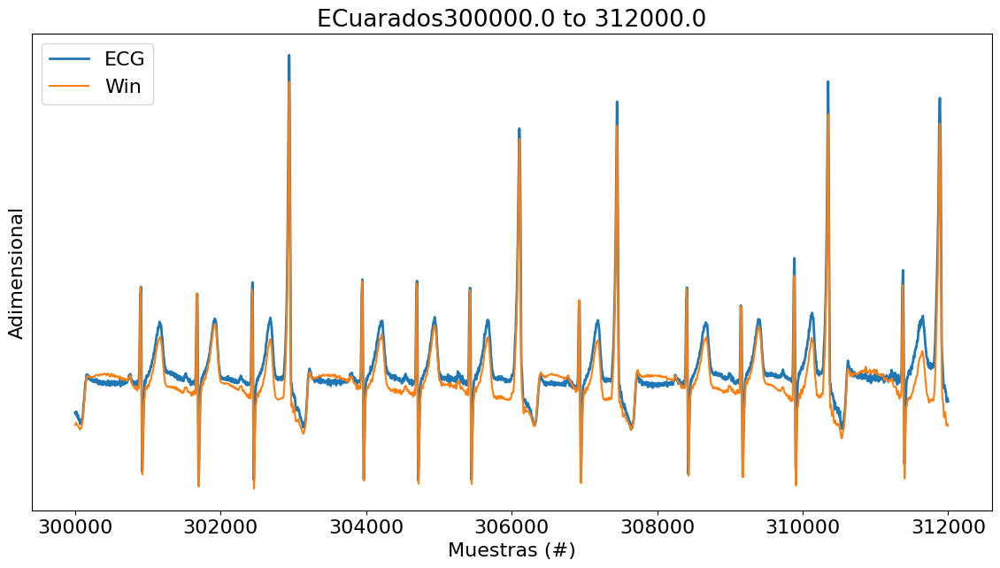

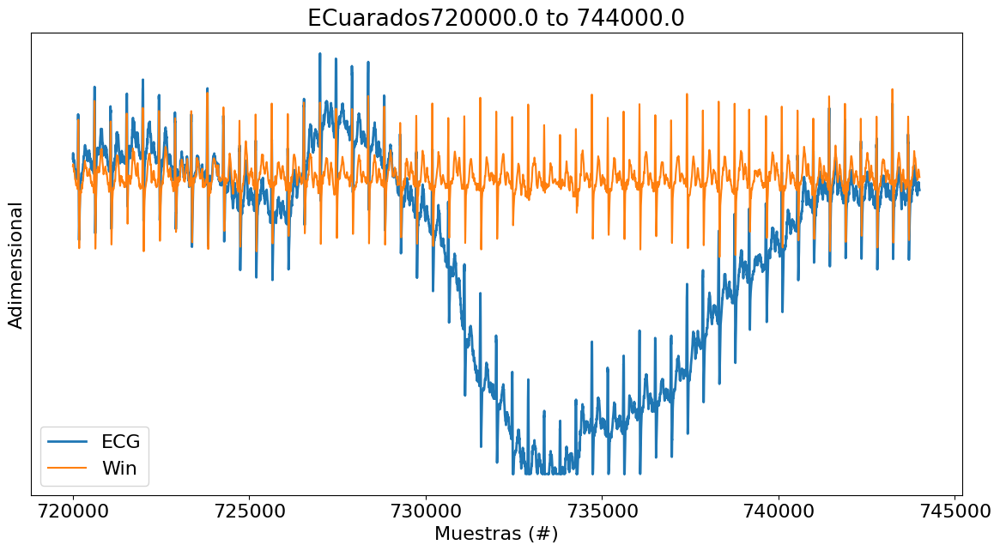

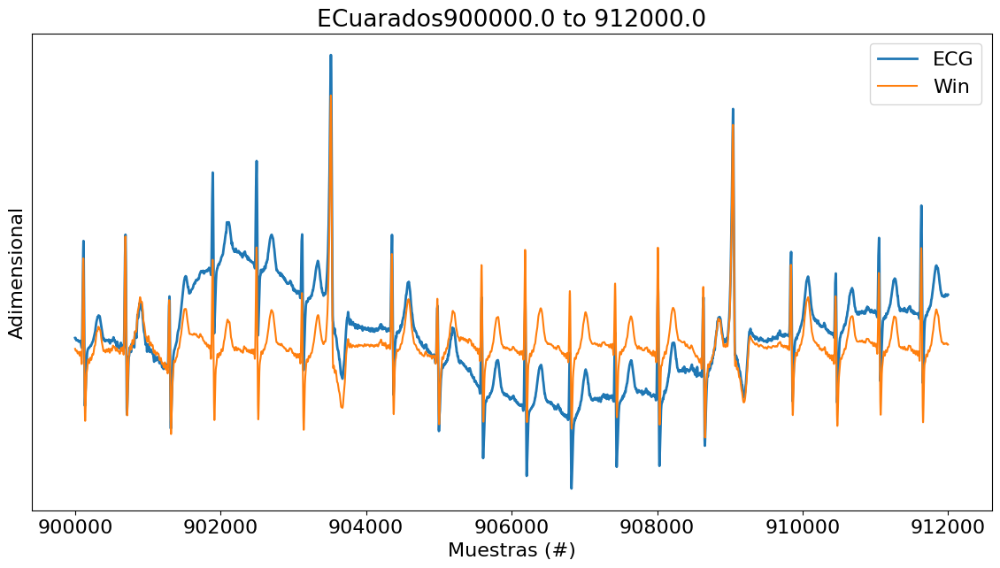

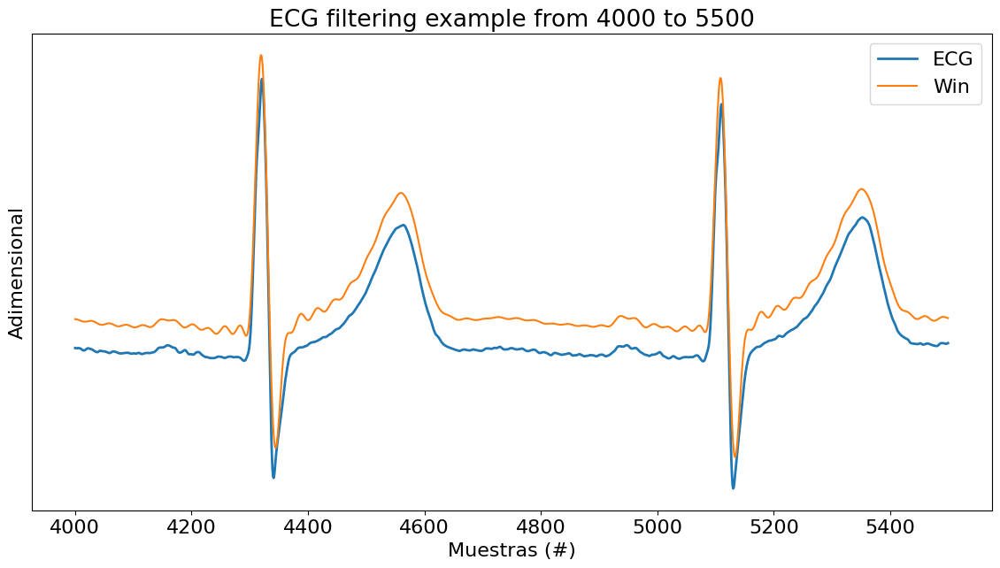

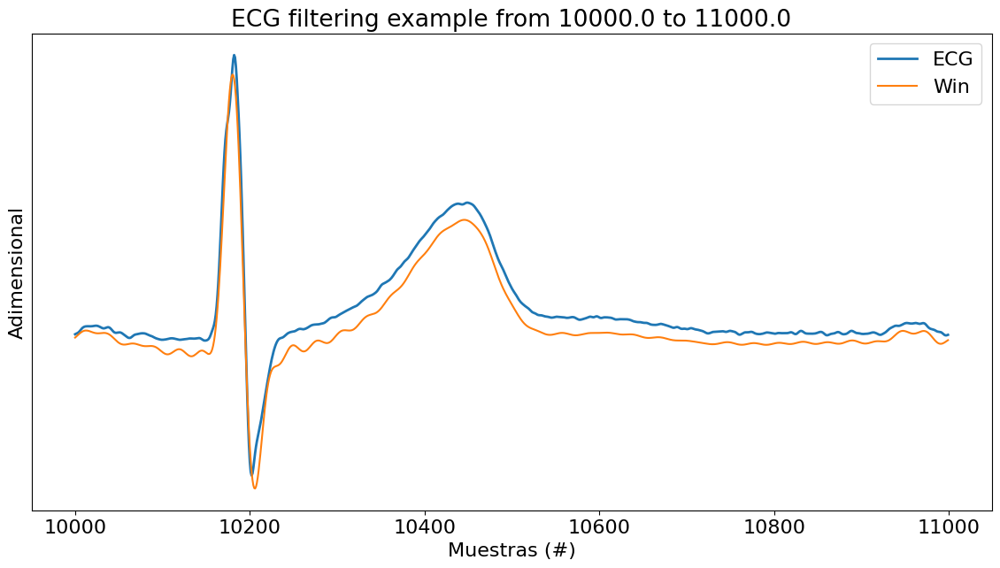

In [34]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt
import sys
import scipy.io as sio
sys.path.append('/home/ignacio/Escritorio/Facultad/2025/TC2/TC2_Virtual/lib/python3.12/site-packages')

from pytc2.sistemas_lineales import  plot_plantilla, group_delay

import sympy as sp
from scipy.signal.windows import hamming, kaiser, blackmanharris

# Inicialización e importación de módulos

# Módulos para Jupyter
import warnings
warnings.filterwarnings('ignore')

# Módulos importantantes
import scipy.signal as sig
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from pytc2.sistemas_lineales import plot_plantilla

# Tamaño de las figuras
fig_sz_x = 14
fig_sz_y = 7

# Tamaño de la tipografía
fig_font_size = 16

plt.rcParams.update({'font.size':fig_font_size})

###
## Señal de ECG registrada a 1 kHz, con contaminación de diversos orígenes.
###

# para listar las variables que hay en el archivo
#io.whosmat('ecg.mat')
mat_struct = sio.loadmat('ecg.mat')

ecg_one_lead = mat_struct['ecg_lead']
ecg_one_lead = ecg_one_lead.flatten()
cant_muestras = len(ecg_one_lead)

fs = 1000 # Hz
nyq_frec = fs / 2

ripple = 0.5 # dB
atenuacion = 40 # dB

wps1 = .1 #Hz
wpp1 = 1 #Hz
wpp2 = 35 #Hz
wps2 = 45 #Hz

ws1 = .65 #Hz
wp1 = 1 #Hz
wp2 = 35 #Hz
ws2 = 35.8 #Hz

frecs = [0.0, ws1, wp1, wp2, ws2, fs/2]
gains = [0,0,1,1,0,0]

cant_coef = 3001

num_firls = sig.firls(cant_coef, frecs, gains, fs=fs )

# muestreo el filtro donde me interesa verlo según la plantilla.
w  = np.append(np.logspace(-1, 0.8, 250), np.logspace(0.9, 1.6, 250) )
w  = np.append(w, np.linspace(110, nyq_frec, 100, endpoint=True) )

_, win_firls = sig.freqz(num_firls, 1, worN= w, fs = fs)

plt.figure(1, figsize=(fig_sz_x, fig_sz_y))

plt.plot(w, 20 * np.log10(np.abs(win_firls)), label='FIR-NUM'.format(num_firls.shape[0]))


plt.title('FIR ejemplo')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.grid()
plt.axis([0, 60, -60, 5 ]);

axes_hdl = plt.gca()
axes_hdl.legend()

plot_plantilla(filter_type = 'bandpass', fpass = (wpp1, wpp2), fstop =  (wps1, wps2), ripple = ripple, attenuation = atenuacion, fs = fs)
    
    
# sobreimprimimos la plantilla del filtro requerido para mejorar la visualización    
fig = plt.figure(1)    
plot_plantilla(filter_type = 'bandpass', fpass = (wpp1, wpp2), fstop =  (wps1, wps2), ripple = ripple, attenuation = atenuacion, fs = fs)
ax = plt.gca()
ax.legend()

ECG_f_win = sig.lfilter(num_firls, 1, ecg_one_lead)

# demora = int(...)
# calcule la demora para cada caso, dicha demora adelantará la señal de salida, como puede ver más abajo.
demora = 1500


# Segmentos de interés con ALTA contaminación

regs_interes = ( 
        np.array([5, 5.2]) *60*fs, # minutos a muestras
        np.array([12, 12.4]) *60*fs, # minutos a muestras
        np.array([15, 15.2]) *60*fs, # minutos a muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    #plt.plot(zoom_region, ECG_f_butt[zoom_region], label='Butter')
    plt.plot(zoom_region, ECG_f_win[zoom_region + demora], label='Win')
    
    plt.title('ECuarados' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

regs_interes = ( 
        [4000, 5500], # muestras
        [10e3, 11e3], # muestras
        )

for ii in regs_interes:
    
    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras, ii[1]]), dtype='uint')
    
    plt.figure(figsize=(fig_sz_x, fig_sz_y), facecolor='w', edgecolor='k')
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    #plt.plot(zoom_region, ECG_f_butt[zoom_region], label='Butter')
    plt.plot(zoom_region, ECG_f_win[zoom_region + demora], label='Win')
    
    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')
    
    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())
            
    plt.show()

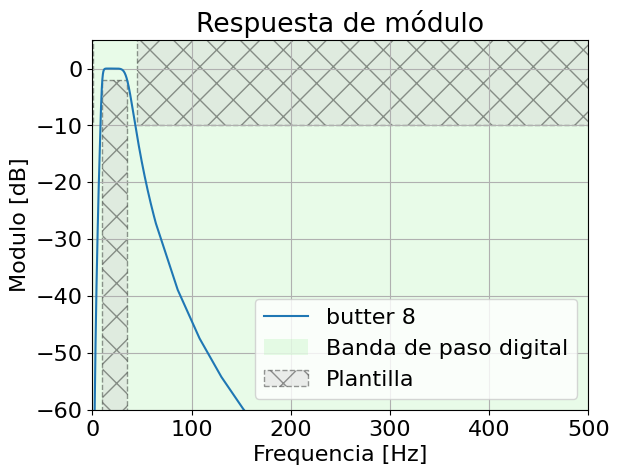

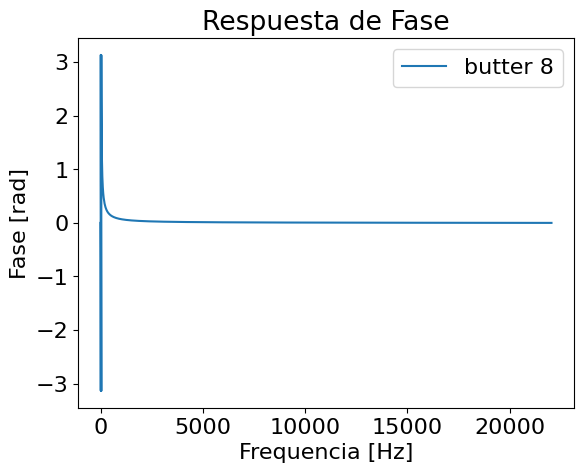

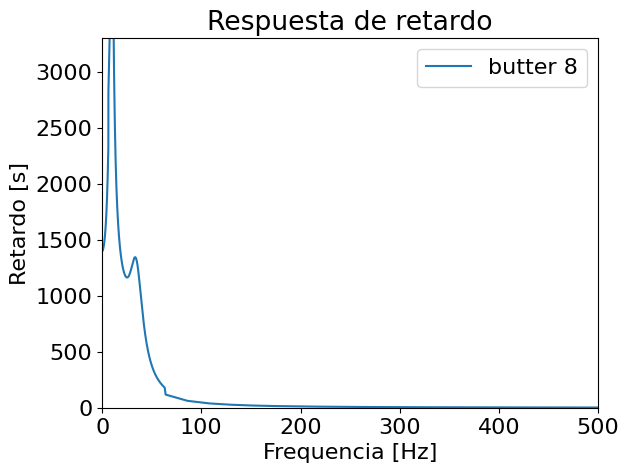

Coeficientes en formato [b0 b1 b2 -a1 -a2]:
[1.3089029244130391e-11, 2.6178058488260783e-11, 1.3089029244130391e-11, 1.9953166586795115, -0.995330729325073]
[1.0, 2.0, 1.0, 1.9976415138465917, -0.997645088718124]
[1.0, -2.0, 1.0, 1.997702058393566, -0.9977272926953706]
[1.0, -2.0, 1.0, 1.9993583197893436, -0.9993603172405445]


In [35]:
import numpy as np
import scipy.signal as sig
import matplotlib.pyplot as plt
import sys
sys.path.append('/home/ignacio/Escritorio/Facultad/2025/TC2/TC2_Virtual/lib/python3.12/site-packages')

from pytc2.sistemas_lineales import  plot_plantilla, group_delay


def plot_iir_response(sos_iir, iir_lbl = 'un_IIR'):

    w_rad  = np.append(np.logspace(-3, 0.8, 1000), np.logspace(0.9, 1.8, 1000) )
    w_rad  = np.append(w_rad, np.linspace(64, nyq_frec, 1000, endpoint=True) ) / nyq_frec * np.pi
    
    _, h_iir = sig.freqz_sos(sos_iir, worN=w_rad)
    
    w = w_rad / np.pi * nyq_frec
    
    this_lbl = iir_lbl + ' {:d}'.format(sos_iir.shape[0]*2)
    
    plt.figure(1)
    
    plt.plot(w, 20*np.log10(np.abs(h_iir)+1e-12), label= this_lbl )
                
    plt.figure(2)
    
    phase_fir = np.angle(h_iir)
    
    plt.plot(w, phase_fir, label= this_lbl)    # Bode phase plot
    
    plt.figure(3)
    
    gd_fir = group_delay(w_rad, phase_fir)
    
    # Para órdenes grandes 
    plt.plot(w[gd_fir > 0], gd_fir[gd_fir>0], label=this_lbl )    # Bode phase plot
    
    return int(np.round(np.median(gd_fir[np.bitwise_and(w > 3, w < 20)])))


fs = 44100 # Hz
nyq_frec = fs / 2

# filter design
ripple = 2 # dB
atenuacion = 10 # dB

ws1 = 1 #Hz
wp1 = 10 #Hz
wp2 = 35.0 #Hz
ws2 = 45.0 #Hz


aprox_name = 'butter'
# aprox_name = 'cheby1'
# aprox_name = 'cheby2'
# aprox_name = 'ellip'

# Requerimientos de plantilla

# filter_type = 'lowpass'
# filter_type = 'highpass'
filter_type = 'bandpass'
# filter_type = 'bandstop'

# plantillas normalizadas a Nyquist y en dB

if filter_type == 'lowpass':

    # wp = 1/2/np.pi # 
    wp = wp2 # 
    ripple = 0.5 # dB
    ws = ws2 # Hz
    attenuation = 40 # dB

elif filter_type == 'highpass':

    wp = wp2
    ripple = 0.5 # dB
    ws = ws1
    attenuation = 40 # dB

elif filter_type == 'bandpass':

    wp = np.array( [wp1, wp2] ) 
    ripple = 2 # dB
    ws = np.array( [ws1, ws2] ) 
    attenuation = 10 # dB
    
else:

    # bandstop
    ws = np.array( [wp1, wp2] ) 
    ripple = 0.5 # dB
    wp = np.array( [ws1, ws2] ) 
    attenuation = 40 # dB




bp_sos_iir = sig.iirdesign(wp=wp, ws=ws, gpass=ripple, gstop=attenuation, output='sos', analog=False, ftype=aprox_name, fs = fs)
cant_coef = plot_iir_response(bp_sos_iir, iir_lbl = aprox_name)


# Plantilla y finalización de figuras.

plt.figure(1)

plot_plantilla(filter_type = filter_type, fpass = wp , ripple = ripple , fstop = ws, attenuation = atenuacion, fs = fs)

plt.title('Respuesta de módulo')
plt.xlabel('Frequencia [Hz]')
plt.ylabel('Modulo [dB]')
plt.axis([0, 500, -60, 5 ]);

axes_hdl = plt.gca()
axes_hdl.legend()

plt.grid()

            
plt.figure(2)

plt.title('Respuesta de Fase')
plt.xlabel('Frequencia [Hz]')
plt.ylabel('Fase [rad]')

axes_hdl = plt.gca()
axes_hdl.legend()


plt.figure(3)

plt.axis([0, 500, 0, cant_coef*3/2])

plt.title('Respuesta de retardo')
plt.xlabel('Frequencia [Hz]')
plt.ylabel('Retardo [s]')

axes_hdl = plt.gca()
axes_hdl.legend()

plt.show()

bp_sos_iir = sig.iirdesign(
    wp=wp, ws=ws,
    gpass=ripple, gstop=attenuation,
    output='sos', analog=False,
    ftype=aprox_name, fs=fs
)

coef_list = []
for sec in bp_sos_iir:
    b0, b1, b2, a0, a1, a2 = sec
    coef_list.append([float(b0), float(b1), float(b2), float(-a1), float(-a2)])

print("Coeficientes en formato [b0 b1 b2 -a1 -a2]:")
for c in coef_list:
    print(c)

### Conclusiones
Tuvimos inconveniente en la parte practica de laboratorio con el STM Nucleo-64, ya que al pasarle los coeficientes no hacia nada, debido a la cantidad de coeficietnes que teniamos. Hemos podido filtrar digitalmente una señal de ECG, eliminando perfectamente el ruido y sin cambiar la fase.